# Tarea 2 · Parte 2 — Evaluación, extracción estructurada y comparación de modelos

**Protocolo (fijado antes de calcular métricas):**
- Muestra de **10 documentos** (3 impresos, 4 fotos, 3 manuscritos) y **10 clips** de OpenSLR 73 (10 hablantes distintos, 5 mujeres y 5 hombres), todos del corpus de la Parte 1. Las grabaciones de Commons (ruido, música, varios hablantes) no tienen referencia manual completa, por lo que se analizan aparte como *caso difícil* mediante el desacuerdo entre modelos.
- Las configuraciones de todos los modelos son las de la Parte 1 y no se tocaron después de ver métricas.
- Normalización idéntica para referencia e hipótesis: minúsculas, sin tildes, sin puntuación, espacios colapsados; en audio se eliminan marcas `[HABLANTE_n]`.
- **Origen de las referencias:** en audio, el texto humano de OpenSLR 73 (guion leído por cada hablante, revisado contra el audio); en documentos, transcripción manual hecha mirando la imagen (columna `estado_revision`).

In [1]:
import sys, json, re, unicodedata
import pandas as pd, numpy as np, jiwer
import plotly.express as px, plotly.io as pio
pio.renderers.default = "notebook_connected+png"
sys.path.insert(0, "pipeline")
import ocr, voz
docs = pd.read_csv("datos/documentos.csv"); trans = pd.read_csv("datos/transcripciones.csv")
def norm(t):
    t = re.sub(r"\[HABLANTE_[^\]]*\]", " ", str(t))
    t = unicodedata.normalize("NFKD", t.lower())
    t = "".join(c for c in t if not unicodedata.combining(c))
    t = re.sub(r"[^a-zñ0-9 ]", " ", t.replace("ñ", "ñ"))
    return re.sub(r"\s+", " ", t).strip()
cer = lambda r, h: jiwer.cer(norm(r), norm(h)) if norm(h) else 1.0
wer = lambda r, h: jiwer.wer(norm(r), norm(h)) if norm(h) else 1.0

## 1. Muestra de evaluación y referencias manuales

In [2]:
ref_doc = pd.read_csv("datos/referencias_documentos.csv")
EVAL_DOCS = ref_doc.id.tolist()
ref_ol = pd.read_csv("datos/referencia_openslr.csv")
ref_cm = pd.read_csv("datos/referencias_audio_commons.csv") if __import__("os").path.exists("datos/referencias_audio_commons.csv") else pd.DataFrame(columns=["id","texto_referencia","estado_revision"])
EVAL_OL = ["clip_001", "clip_003", "clip_005", "clip_007", "clip_009", "clip_011", "clip_013", "clip_015", "clip_017", "clip_019"]  # 5 mujeres + 5 hombres, hablantes distintos
ref_aud = pd.concat([ref_ol[ref_ol.id.isin(EVAL_OL)].rename(columns={"referencia_fuente": "texto_referencia"}).assign(estado_revision="transcripción humana OpenSLR"),
                     ref_cm], ignore_index=True)
EVAL_AUD = ref_aud.id.tolist()
docs = docs.drop(columns="texto_referencia").merge(ref_doc[["id", "texto_referencia"]], on="id", how="left")
trans = trans.drop(columns="texto_referencia").merge(ref_aud[["id", "texto_referencia"]], on="id", how="left")
docs.to_csv("datos/documentos.csv", index=False, encoding="utf-8"); trans.to_csv("datos/transcripciones.csv", index=False, encoding="utf-8")
print("Documentos de evaluación:", docs[docs.id.isin(EVAL_DOCS)].tipo.value_counts().to_dict())
print("Clips de evaluación:", len(EVAL_AUD)); display(ref_aud[["id", "estado_revision"]])

Documentos de evaluación: {'foto': 4, 'impreso': 3, 'manuscrito': 3}
Clips de evaluación: 10


,id,estado_revision
0,clip_001,transcripción humana OpenSLR
1,clip_003,transcripción humana OpenSLR
2,clip_005,transcripción humana OpenSLR
3,clip_007,transcripción humana OpenSLR
4,clip_009,transcripción humana OpenSLR
5,clip_011,transcripción humana OpenSLR
6,clip_013,transcripción humana OpenSLR
7,clip_015,transcripción humana OpenSLR
8,clip_017,transcripción humana OpenSLR
9,clip_019,transcripción humana OpenSLR


## 2. Línea base: PaddleOCR (sin personalización) y faster-whisper `small` CPU

In [3]:
ed = docs[docs.id.isin(EVAL_DOCS)].copy()
ed["CER_paddle"] = [cer(r.texto_referencia, ocr.paddle(r.archivo)["texto"]) for r in ed.itertuples()]
ea = trans[trans.id.isin(EVAL_AUD)].copy()
ea["WER_whisper"] = [wer(r.texto_referencia, voz.whisper(r.archivo_audio)["texto"]) for r in ea.itertuples()]
ea["RTF_whisper"] = [voz.whisper(r.archivo_audio)["segundos_proceso"] / r.duracion_seg for r in ea.itertuples()]
print(f"LÍNEA BASE  CER PaddleOCR = {ed.CER_paddle.mean():.3f}   |   WER whisper-small = {ea.WER_whisper.mean():.3f}")

LÍNEA BASE  CER PaddleOCR = 0.476   |   WER whisper-small = 0.032


## 3. Modelos alternativos sobre las mismas muestras

- **Documentos:** dos OCR alternativos: **Tesseract 5** (LSTM, `spa` de *tessdata_best*, `--psm 3`) y **EasyOCR** (detector CRAFT + reconocedor CRNN, `lang=es`). Mismo preprocesamiento que PaddleOCR (EXIF, RGB, lado ≤ 1600 px). Los tiempos se midieron con la CPU sin otros procesos.
- **Audio:** NVIDIA Parakeet-TDT 0.6B v3 (multilingüe, incluye español) en ONNX int8 vía sherpa-onnx, con VAD Silero. RTF = tiempo de proceso / duración.

In [4]:
ed["CER_easyocr"] = [cer(r.texto_referencia, ocr.easyocr(r.archivo)["texto"]) for r in ed.itertuples()]
ed["CER_tesseract"] = [cer(r.texto_referencia, ocr.tesseract(r.archivo)["texto"]) for r in ed.itertuples()]
ed["seg_tesseract"] = [ocr.tesseract(r.archivo)["segundos_proceso"] for r in ed.itertuples()]
ea["WER_parakeet"] = [wer(r.texto_referencia, voz.parakeet(r.archivo_audio)["texto"]) for r in ea.itertuples()]
ea["RTF_parakeet"] = [voz.parakeet(r.archivo_audio)["segundos_proceso"] / r.duracion_seg for r in ea.itertuples()]
ed["seg_paddle"] = [ocr.paddle(r.archivo)["segundos_proceso"] for r in ed.itertuples()]
ed["seg_easyocr"] = [ocr.easyocr(r.archivo)["segundos_proceso"] for r in ed.itertuples()]
display(ed[["id", "tipo", "CER_paddle", "CER_easyocr", "CER_tesseract", "seg_paddle", "seg_easyocr", "seg_tesseract"]].round(3))
display(ea[["id", "condicion", "WER_whisper", "WER_parakeet", "RTF_whisper", "RTF_parakeet"]].round(3))

,id,tipo,CER_paddle,CER_easyocr,CER_tesseract,seg_paddle,seg_easyocr,seg_tesseract
5,doc_006,impreso,0.490,0.582,0.641,5.064,28.033,1.138
6,doc_007,impreso,0.314,0.662,0.795,4.649,26.449,1.715
7,doc_008,impreso,0.620,0.740,0.969,8.662,26.351,1.226
12,doc_013,foto,0.037,0.103,0.246,10.669,38.078,8.318
13,doc_014,foto,0.382,0.587,0.833,6.935,32.683,1.329
14,doc_015,foto,0.061,0.061,0.117,2.473,27.071,1.201
15,doc_016,foto,0.425,0.345,0.690,2.459,28.442,1.266
21,doc_022,manuscrito,0.881,0.751,0.766,4.935,38.169,4.623
22,doc_023,manuscrito,0.702,0.609,0.821,5.068,9.984,1.390
24,doc_025,manuscrito,0.851,0.852,0.844,5.370,30.248,2.384


,id,condicion,WER_whisper,WER_parakeet,RTF_whisper,RTF_parakeet
0,clip_001,lectura en estudio (crowdsourcing),0.031,0.012,0.488,0.162
2,clip_003,lectura en estudio (crowdsourcing),0.045,0.000,0.300,0.156
4,clip_005,lectura en estudio (crowdsourcing),0.013,0.065,0.385,0.172
6,clip_007,lectura en estudio (crowdsourcing),0.015,0.037,0.359,0.142
8,clip_009,lectura en estudio (crowdsourcing),0.021,0.036,0.816,0.177
10,clip_011,lectura en estudio (crowdsourcing),0.025,0.042,0.494,0.132
12,clip_013,lectura en estudio (crowdsourcing),0.019,0.064,0.494,0.180
14,clip_015,lectura en estudio (crowdsourcing),0.097,0.090,0.478,0.159
16,clip_017,lectura en estudio (crowdsourcing),0.031,0.031,0.436,0.183
18,clip_019,lectura en estudio (crowdsourcing),0.018,0.012,0.543,0.206


## 4. Tabla comparativa y casos difíciles

In [5]:
tabla = pd.DataFrame([
    {"modalidad": "documentos", "modelo": "PaddleOCR PP-OCRv5 (base)", "métrica": "CER", "valor": ed.CER_paddle.mean(), "costo": f"{ed.seg_paddle.mean():.1f} s/doc CPU"},
    {"modalidad": "documentos", "modelo": "EasyOCR (alternativo)", "métrica": "CER", "valor": ed.CER_easyocr.mean(), "costo": f"{ed.seg_easyocr.mean():.1f} s/doc CPU"},
    {"modalidad": "documentos", "modelo": "Tesseract 5 spa (alternativo)", "métrica": "CER", "valor": ed.CER_tesseract.mean(), "costo": f"{ed.seg_tesseract.mean():.1f} s/doc CPU"},
    {"modalidad": "audio", "modelo": "faster-whisper small (base)", "métrica": "WER", "valor": ea.WER_whisper.mean(), "costo": f"RTF {ea.RTF_whisper.mean():.2f}"},
    {"modalidad": "audio", "modelo": "Parakeet-TDT 0.6B v3 (alternativo)", "métrica": "WER", "valor": ea.WER_parakeet.mean(), "costo": f"RTF {ea.RTF_parakeet.mean():.2f}"}])
tabla["valor"] = tabla.valor.round(3)
tabla.to_csv("datos/metricas.csv", index=False, encoding="utf-8")
ed[["id","tipo","CER_paddle","CER_easyocr","CER_tesseract"]].to_csv("datos/metricas_documentos.csv", index=False)
ea[["id","condicion","WER_whisper","WER_parakeet","RTF_whisper","RTF_parakeet"]].to_csv("datos/metricas_audio.csv", index=False)
tabla

,modalidad,modelo,métrica,valor,costo
0,documentos,PaddleOCR PP-OCRv5 (base),CER,0.476,5.6 s/doc CPU
1,documentos,EasyOCR (alternativo),CER,0.529,28.6 s/doc CPU
2,documentos,Tesseract 5 spa (alternativo),CER,0.672,2.5 s/doc CPU
3,audio,faster-whisper small (base),WER,0.032,RTF 0.48
4,audio,Parakeet-TDT 0.6B v3 (alternativo),WER,0.039,RTF 0.17


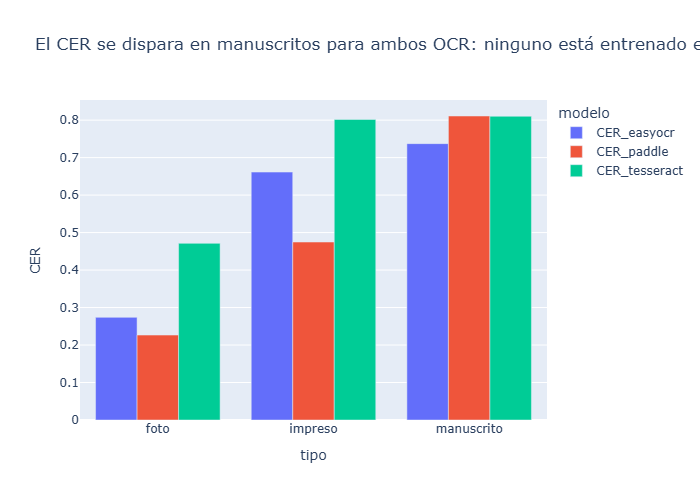

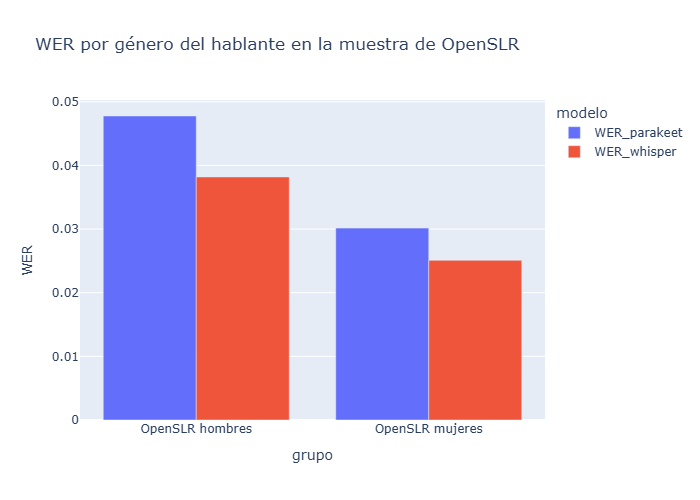

In [6]:
fig = px.bar(ed.melt(id_vars=["id","tipo"], value_vars=["CER_paddle","CER_easyocr","CER_tesseract"], var_name="modelo", value_name="CER")
             .groupby(["tipo","modelo"], as_index=False).CER.mean(), x="tipo", y="CER", color="modelo", barmode="group",
             title="El CER se dispara en manuscritos para ambos OCR: ninguno está entrenado en letra colonial")
fig.show()
ea["grupo"] = np.where(ea.id.isin(["clip_001","clip_003","clip_005","clip_007","clip_009"]), "OpenSLR mujeres", "OpenSLR hombres")
fig = px.bar(ea.melt(id_vars=["id","grupo"], value_vars=["WER_whisper","WER_parakeet"], var_name="modelo", value_name="WER")
             .groupby(["grupo","modelo"], as_index=False).WER.mean(), x="grupo", y="WER", color="modelo", barmode="group",
             title="WER por género del hablante en la muestra de OpenSLR")
fig.show()

In [7]:
print("Por tipo de documento:"); display(ed.groupby("tipo")[["CER_paddle","CER_easyocr","CER_tesseract"]].mean().round(3))
print("Por tipo de audio:"); display(ea.groupby("grupo")[["WER_whisper","WER_parakeet"]].mean().round(3))

Por tipo de documento:


,CER_paddle,CER_easyocr,CER_tesseract
tipo,,,
foto,0.227,0.274,0.471
impreso,0.475,0.661,0.802
manuscrito,0.811,0.737,0.810


Por tipo de audio:


,WER_whisper,WER_parakeet
grupo,,
OpenSLR hombres,0.038,0.048
OpenSLR mujeres,0.025,0.030


### Caso difícil: entrevistas con ruido, música y varios hablantes (Commons)
Sin referencia manual completa no se reporta WER; como indicador se usa el **desacuerdo entre modelos** (WER de Parakeet tomando a whisper como pseudo-referencia). Un valor alto indica que al menos uno de los dos falla. **No es una métrica de exactitud.**

In [8]:
PRIVADOS = json.load(open("datos/raw/privados.json", encoding="utf-8"))  # mismo diccionario no versionado del notebook 01
def seud(t):
    for real, s in PRIVADOS.items():
        t = re.sub(r"\b" + re.escape(real) + r"\b", s, t, flags=re.I)
    return t
cm = trans[trans.origen.str.startswith("Wikimedia")].copy()
cm["desacuerdo_modelos"] = [wer(voz.whisper(r.archivo_audio)["texto"], voz.parakeet(r.archivo_audio)["texto"]) for r in cm.itertuples()]
ol = trans[trans.id.isin(EVAL_AUD)].copy()
ol["desacuerdo_modelos"] = [wer(voz.whisper(r.archivo_audio)["texto"], voz.parakeet(r.archivo_audio)["texto"]) for r in ol.itertuples()]
print(f"Desacuerdo medio whisper vs Parakeet — OpenSLR: {ol.desacuerdo_modelos.mean():.2f} | Commons: {cm.desacuerdo_modelos.mean():.2f}")
display(cm[["id", "condicion", "n_hablantes", "desacuerdo_modelos"]].round(2))
for r in cm.iloc[[0, 2]].itertuples():
    print("---", r.id, r.condicion)
    print("whisper :", seud(voz.whisper(r.archivo_audio)["texto"])[:300])
    print("parakeet:", seud(voz.parakeet(r.archivo_audio)["texto"])[:300])
pd.DataFrame([{"id": r.id, "texto": seud(voz.parakeet(r.archivo_audio)["texto"])} for r in trans.itertuples()]).to_csv(
    "datos/transcripciones_parakeet.csv", index=False, encoding="utf-8")

Desacuerdo medio whisper vs Parakeet — OpenSLR: 0.04 | Commons: 0.36


,id,condicion,n_hablantes,desacuerdo_modelos
20,clip_021,exterior/ruido (calle),3,0.17
21,clip_022,"exterior/ruido (evento), nivel bajo (-40 dB me...",2,0.73
22,clip_023,ruido/música (feria),2,0.66
23,clip_024,ruido/música (feria gastronómica),2,0.20
24,clip_025,"exterior (conferencia de prensa, Plaza San Mar...",2,0.08
25,clip_026,estudio/casero (lectura),1,0.29


--- clip_021 exterior/ruido (calle)
whisper : Buenos días profesor y compañeros. Hoy estoy cerca de aquí por mi casa y voy a hacer entrevistas cerca del fútbol como unión de masas. Estoy con las señoras PERSONA_A. ¿Estáis PERSONA_B? Muy bien. Voy a comenzar con la primera pregunta y es ¿qué expectativas tienen ante este partido? Que la afición 
parakeet: Buenos días, profesor y compañeros. Hoy estoy cerca de aquí por mi casa y voy a hacer la entrevista acerca de fútbol como unión de masas. Estoy con las señoras Sal PERSONA_A. De Savarriento. Muy bien, voy a comenzar con la primera pregunta y es ¿qué expectativas tienen ante este partido? Yeah. que l
--- clip_023 ruido/música (feria)
whisper : A ver, comenzando. ¿Qué es el Perú para usted? ¿Qué es el Perú para mí? Bueno, es mi patria, es donde he crecido, es donde sigo desarrollándome y es el lugar donde también me siento parte de la cultura pebana. ¿Cuáles son sus características principales y positivas para usted? que que del país, sí

## 5. Extracción estructurada con LLM

In [9]:
import os
from dotenv import load_dotenv; load_dotenv("../.env"); load_dotenv(".env")
HAY_LLM = bool(os.environ.get("GEMINI_API_KEY"))
print("API key de Gemini disponible:", HAY_LLM)
# gemini-3.1-flash-lite: se usó un único modelo para las 51 extracciones (la cuota gratuita de gemini-3.5-flash se agotó a mitad del proceso)
if HAY_LLM:
    import llm
    filas = [llm.extraer(r.id, r.texto_ocr, "documento") for r in docs.itertuples()] + \
            [llm.extraer(r.id, r.texto_asr, "audio") for r in trans.itertuples()]
    ext = pd.DataFrame([{"id": f["id"], "modalidad": f["modalidad"], "campos_json": json.dumps(f["campos"], ensure_ascii=False),
                         "modelo_llm": f["modelo_llm"], "fecha": f["fecha"]} for f in filas])
    ext.to_csv("datos/extraccion_llm.csv", index=False, encoding="utf-8")
    display(ext.head())

API key de Gemini disponible: True


,id,modalidad,campos_json,modelo_llm,fecha
0,doc_001,documento,"{""modalidad"": ""documento"", ""tema"": ""Tratado de...","gemini-3.1-flash-lite (temperature=0, JSON)",2026-10-26
1,doc_002,documento,"{""modalidad"": ""documento"", ""tema"": ""Decreto so...","gemini-3.1-flash-lite (temperature=0, JSON)",2026-10-26
2,doc_003,documento,"{""modalidad"": ""documento"", ""tema"": ""Índice de ...","gemini-3.1-flash-lite (temperature=0, JSON)",2026-10-26
3,doc_004,documento,"{""modalidad"": ""documento"", ""tema"": ""Descripció...","gemini-3.1-flash-lite (temperature=0, JSON)",2026-10-26
4,doc_005,documento,"{""modalidad"": ""documento"", ""tema"": ""Lista de n...","gemini-3.1-flash-lite (temperature=0, JSON)",2026-10-26


## 6. Auditoría humana de 20 extracciones

Criterios: una extracción es **completamente correcta** si (a) `tema` y `resumen` son fieles al texto, (b) todo campo no nulo está sustentado literalmente en el texto, (c) no se omiten datos explícitos del texto (`fecha`, `emisor`, `monto`) y (d) no hay campos inventados. Muestra: 10 documentos + 10 audios al azar (`DataFrame.sample(10, random_state=7)` en cada corpus). Para `citas_clave` y `lugares_mencionados` se verificó por código que cada cadena aparezca literalmente en el texto.

**Quién revisó:** la revisión campo por campo la hizo el asistente de IA (Claude Code), comparando cada campo con el texto OCR/ASR. La columna `revisor` de `datos/auditoria_llm.csv` lo indica; la estudiante debe confirmarla o corregirla.

In [10]:
muestra = pd.concat([docs.sample(10, random_state=7)[["id"]], trans.sample(10, random_state=7)[["id"]]]).id.tolist()
print(muestra)

['doc_002', 'doc_006', 'doc_012', 'doc_014', 'doc_003', 'doc_022', 'doc_010', 'doc_017', 'doc_013', 'doc_001', 'clip_013', 'clip_006', 'clip_002', 'clip_018', 'clip_012', 'clip_010', 'clip_003', 'clip_024', 'clip_026', 'clip_014']


Resultado:

In [11]:
if os.path.exists("datos/auditoria_llm.csv"):
    aud_llm = pd.read_csv("datos/auditoria_llm.csv")
    ok = int(aud_llm.correcto.sum())
    print(f"Acuerdo LLM-Humano: {ok}/20 = {ok/20:.0%}")
    display(aud_llm[aud_llm.correcto == 0][["id", "error"]])
else:
    print("Auditoría pendiente")

Acuerdo LLM-Humano: 16/20 = 80%


,id,error
2,doc_012,fecha = 'SETIENBRE INTS': copia literal de rui...
6,doc_010,fecha = '1. de Setiembre de 1926' inventada: e...
9,doc_001,emisor = 'Antonio José de Sucre' y lugar = 'Ay...
18,clip_026,citas_clave[1] no es textual: el LLM cambió 'p...


## 7. Decisión y reflexión

In [12]:
print(tabla.to_string(index=False))

 modalidad                             modelo métrica  valor          costo
documentos          PaddleOCR PP-OCRv5 (base)     CER  0.476  5.6 s/doc CPU
documentos              EasyOCR (alternativo)     CER  0.529 28.6 s/doc CPU
documentos      Tesseract 5 spa (alternativo)     CER  0.672  2.5 s/doc CPU
     audio        faster-whisper small (base)     WER  0.032       RTF 0.48
     audio Parakeet-TDT 0.6B v3 (alternativo)     WER  0.039       RTF 0.17


### Decisión
| Modalidad | Elección | Por qué |
|---|---|---|
| Documentos | **PaddleOCR PP-OCRv5 mobile** | Menor CER global (0.476 frente a 0.529 de EasyOCR y 0.672 de Tesseract) y 5 veces más rápido que EasyOCR en CPU (5.6 frente a 28.6 s/doc). Tesseract es el más rápido (2.5 s/doc), pero su CER en fotos duplica al de PaddleOCR. |
| Audio | **faster-whisper small** como modelo principal; **Parakeet** como alternativa si importa la velocidad | En lectura limpia los dos quedan casi empatados (WER 0.032 frente a 0.039; la diferencia es de unas pocas palabras sobre ~1 400). Parakeet es ~3 veces más rápido (RTF 0.17 frente a 0.48). Whisper entrega puntuación y segmentos más útiles para el SRT y la diarización. |

### Reflexión por tipo
- **Fotos (CER 0.23 con PaddleOCR, el mejor caso).** Las placas tienen letra grande de molde. El error se concentra en la placa de bronce con reflejos (doc_014, CER 0.38) y en la leyenda latina curva (doc_016, 0.43). La placa de Grau, nítida, baja a 0.04.
- **Impresos (0.48).** El CER es más alto de lo esperado porque los 3 impresos evaluados tienen **partes manuscritas o tipografía decorativa**: los datos escritos a mano en el recibo de 1895, la caligrafía inglesa del diploma de 1921 y los textos superpuestos con sello de la acción de 1878. El OCR lee bien las partes tipográficas y falla en lo demás.
- **Manuscritos (0.74–0.81, el peor caso).** Ningún modelo está entrenado en letra colonial de los siglos XVIII y XIX ni en sus abreviaturas. Por eso los tres OCR producen texto casi inutilizable. EasyOCR queda algo mejor, pero el error sigue siendo de 0.74. Para este tipo haría falta un modelo de HTR especializado (por ejemplo, Transkribus o TrOCR afinado) o una transcripción humana.
- **Audio en estudio frente a audio de calle.** Con lectura limpia los dos ASR cometen menos de 4 % de error. En las entrevistas de Commons el desacuerdo entre modelos sube de 0.04 a 0.36 de media, y llega a 0.73 en la conferencia con audio a −40 dB y a 0.66 en la feria con música. Es la señal de que el ruido, la música y el habla superpuesta degradan mucho la transcripción.
- **LLM.** Acertó en 16 de 20 casos. Los errores aparecen cuando el OCR es ruidoso: copió basura como si fuera una fecha, inventó una fecha, confundió el emisor de un documento citado con el del documento, y una vez parafraseó una cita que debía ser textual. Ante un OCR ilegible (doc_017 y doc_022) respondió bien: dejó los campos en `null` y no inventó nada.